In [2]:
import json
from collections import defaultdict
from datetime import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
logfile = "/Users/Katie/Documents/MagAO-X/Data/ADC/2025B/logs/taucet_offset_i.ndjson"

data = defaultdict(list) #default dict will just make a new entry if it doesn't recognize the key

with open(logfile, "r") as f:
    for line in f:
        entry = json.loads(line)

        ts = datetime.fromisoformat(entry["ts"])
        message = entry["msg"]["message"]
        
        if ":" not in message:
            #print("skipping message:", message)
            continue #if there's no colon, you can't split the string

        key, val = message.split(":", 1) #splits the string at the first colon, maxs no. of splits is one so it doesn't split words into multiple vals
        key = key.strip() #strips leading/trailing whitespace
        val = val.strip()

        if val.startswith("["): #speckle angles are vector valued
            numbers = np.fromstring(val.strip("[]"), sep=" ") #remove the brackets, separate values by spaces and put them into an np array
            data[key].append((ts, numbers))
        else:
            try:
                value = float(val) #check if it can be converted to scalar
            except:
                value = str(val) #if not, we save it as a string
            data[key].append((ts, value))

In [4]:
data.keys()

dict_keys(['Logging to /opt/MagAOX/logs/adcCtrl/adcCtrl_20251205030355139264000.ndjson.gz, current human-readable log at', 'Found camera', 'initial normalized wavelength value', 'extent', 'measured speckle angles', 'single error measurement', 'mean error across 1 measurements', 'mean error across 5 measurements', 'delta command', 'total command'])

In [5]:
#mean measurements
mean_times, mean_vals = zip(*data["mean error across 5 measurements"])
mean_times = np.array(mean_times)[2:]
mean_vals = np.array(mean_vals)
mean_vals = np.array([float(v) for v in mean_vals[2:]])

#single measurements
single_times, single_vals = zip(*data['single error measurement'])
single_times = np.array(single_times)
single_times = np.delete(single_times,np.argmin(single_times))

single_vals = -np.array(single_vals)
single_vals = np.delete(single_vals,np.argmin(single_times))

In [14]:
print(mean_times[0].time())
print(mean_times[-1].time())

03:50:41.548088
03:56:16.584789


In [6]:
np.argmin(single_times)

np.int64(0)

Text(0.5, 1.0, '$\\tau$ Ceti ADC')

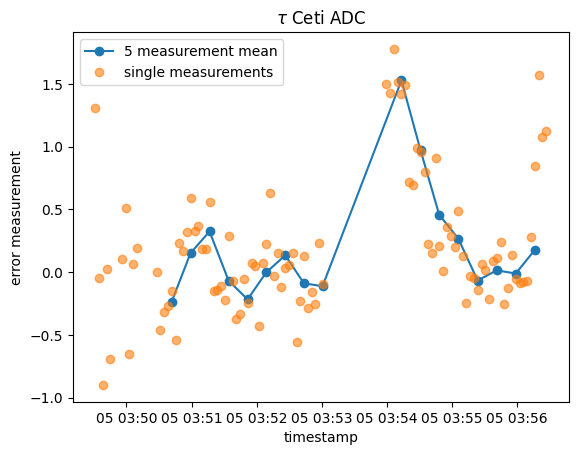

In [7]:
plt.plot(mean_times,mean_vals, 'o-',label='5 measurement mean')
plt.plot(single_times,single_vals,'o',alpha=0.6,label='single measurements')
plt.legend()
plt.xlabel('timestamp')
plt.ylabel('error measurement')
plt.title(r'$\tau$ Ceti ADC')

In [8]:
#scale the values to be in dispersion units
scaled_mean_vals = mean_vals * 5.79
scaled_single_vals = single_vals * 5.79

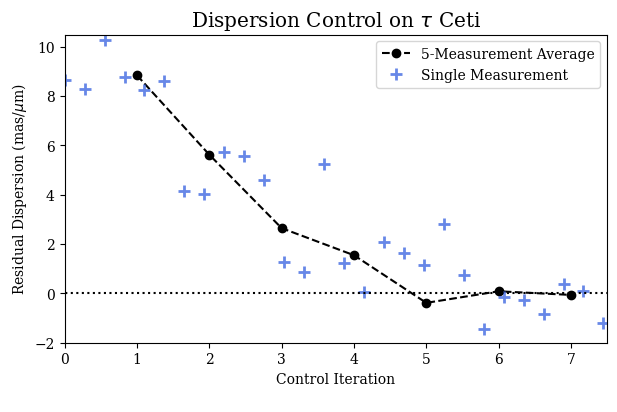

In [14]:
#quick and dirty plot for my SOL poster
plt.rcParams['font.family'] = 'serif'
plt.rcParams['axes.titlesize'] = 'x-large'


fig = plt.figure(figsize=(7,4))
iters = np.arange(7)+1
cutoff = -13
singles = np.linspace(0,8,len(single_times[55:cutoff]))
plt.plot(iters,scaled_mean_vals[-8:-1], 'o--',label='5-Measurement Average',color='black')
plt.plot(singles,scaled_single_vals[55:cutoff],'+',alpha=0.8,label='Single Measurement',color='royalblue',markeredgewidth=2,markersize=8)
plt.hlines(0,-1,9,color='black',linestyles='dotted')
#plt.vlines(1,-2,2,colors='indianred',linestyles='dotted',label='Loop Closed')
plt.xlim((0,7.5))
plt.ylim((-2,10.5))
plt.legend()
plt.xlabel('Control Iteration\n')
plt.ylabel(r'Residual Dispersion (mas/$\mu$m)')
plt.title(r'Dispersion Control on $\tau$ Ceti')

fig.savefig('/Users/Katie/Documents/MagAO-X/figures/ADC/SPIE_26/taucet_convergence',dpi=300)

In [10]:
scaled_mean_vals[-3]

np.float64(0.0796691738355992)